# 01. Data Architecture & High-Dimensional Profiling

> **Role**: Role 2 — Dataset Collection & EDA  
> **Project**: Project 18 — Water Quality Prediction via Gradient Boosting & DNN  
> **Course**: Semester 5 AML / DL  

This notebook explores the dataset scale, structural architecture, spatial station distribution, and multi-country composition across 4,297,895 water quality records (1940–2023).

---

## 1. Setup & Environment
Import necessary analytical libraries and configure publication-quality visualization defaults.

In [ ]:
# Setup and Styling
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'Helvetica', 'Arial', 'DejaVu Sans'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12

print("Environment initialized successfully.")

Environment initialized successfully.


## 2. Load Master Dataset & Memory Profiling
Inspect dimensions, column types, and memory optimization.

In [ ]:
# Load Dataset & Schema Audit
df = pd.read_parquet(DATA_PATH)
print(f"Master Dataset Loaded Successfully!")
print(f"Total Rows:     {len(df):,}")
print(f"Total Columns:  {len(df.columns)}")
mem_mb = df.memory_usage(deep=True).sum() / (1024**2)
print(f"Memory Footprint: {mem_mb:.2f} MB")

schema_df = pd.DataFrame({
    'Column Name': df.columns,
    'Data Type': df.dtypes.astype(str),
    'Non-Null Count': df.notnull().sum(),
    'Null %': (df.isnull().sum() / len(df) * 100).round(2)
}).reset_index(drop=True)
schema_df

Master Dataset Loaded Successfully!
Total Rows:     4,297,895
Total Columns:  14
Memory Footprint: 660.87 MB


## 3. Geographic & Country Breakdown
Analyze monitoring contributions across the 7 nations.

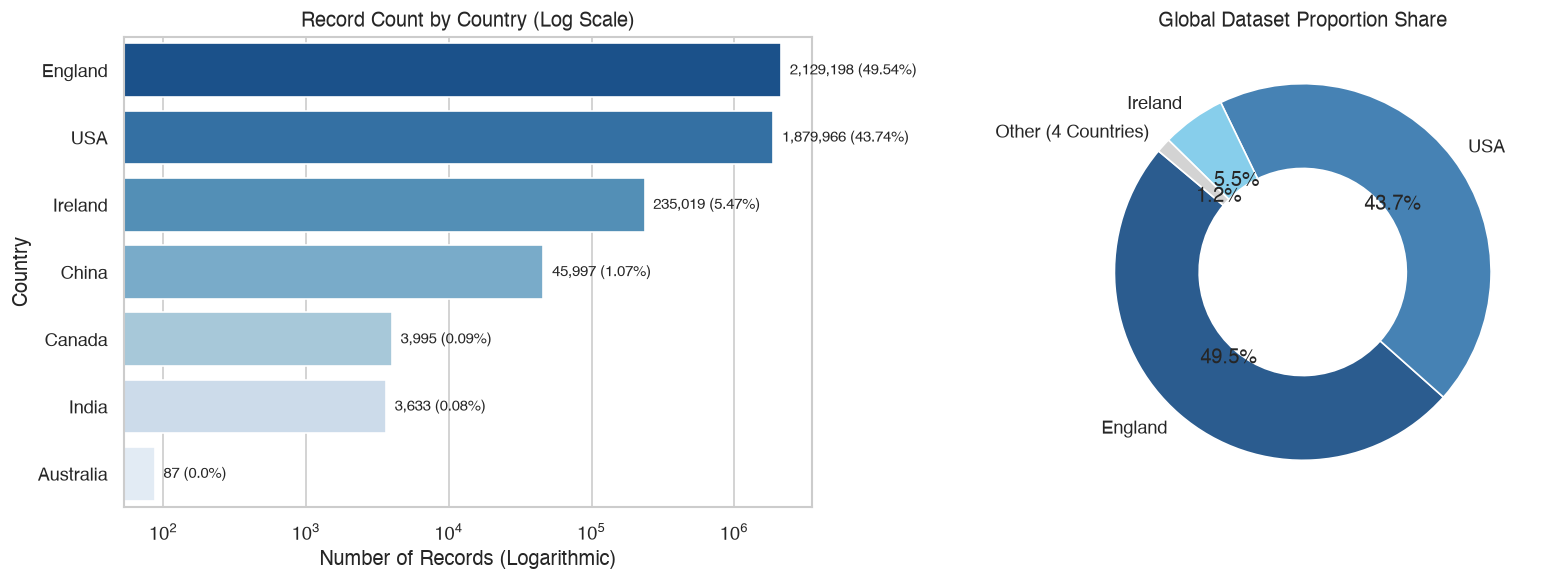

In [ ]:
# Country Distribution Visualization
country_counts = df['Country'].value_counts()
country_pcts = (country_counts / len(df) * 100).round(2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Horizontal Bar Chart
sns.barplot(x=country_counts.values, y=country_counts.index, ax=axes[0], palette='Blues_r', hue=country_counts.index, legend=False)
axes[0].set_xscale('log')
axes[0].set_title('Record Count by Country (Log Scale)')
axes[0].set_xlabel('Number of Records (Logarithmic)')
for i, v in enumerate(country_counts.values):
    axes[0].text(v * 1.15, i, f'{v:,} ({country_pcts.iloc[i]}%)', va='center', fontsize=9)

# Donut Chart for top countries
top_countries = country_counts.head(3)
other_count = country_counts.iloc[3:].sum()
pie_data = pd.concat([top_countries, pd.Series({'Other (4 Countries)': other_count})])
axes[1].pie(pie_data.values, labels=pie_data.index, autopct='%1.1f%%', startangle=140, 
           colors=['#2b5c8f', '#4682b4', '#87ceeb', '#d3d3d3'], wedgeprops=dict(width=0.45, edgecolor='w'))
axes[1].set_title('Global Dataset Proportion Share')

plt.tight_layout()
plt.show()

pd.DataFrame({'Records': country_counts, 'Share (%)': country_pcts})

## 4. Waterbody Type Distribution
Examine the environments monitored (Rivers, Streams, Effluents, Lakes, Marine).

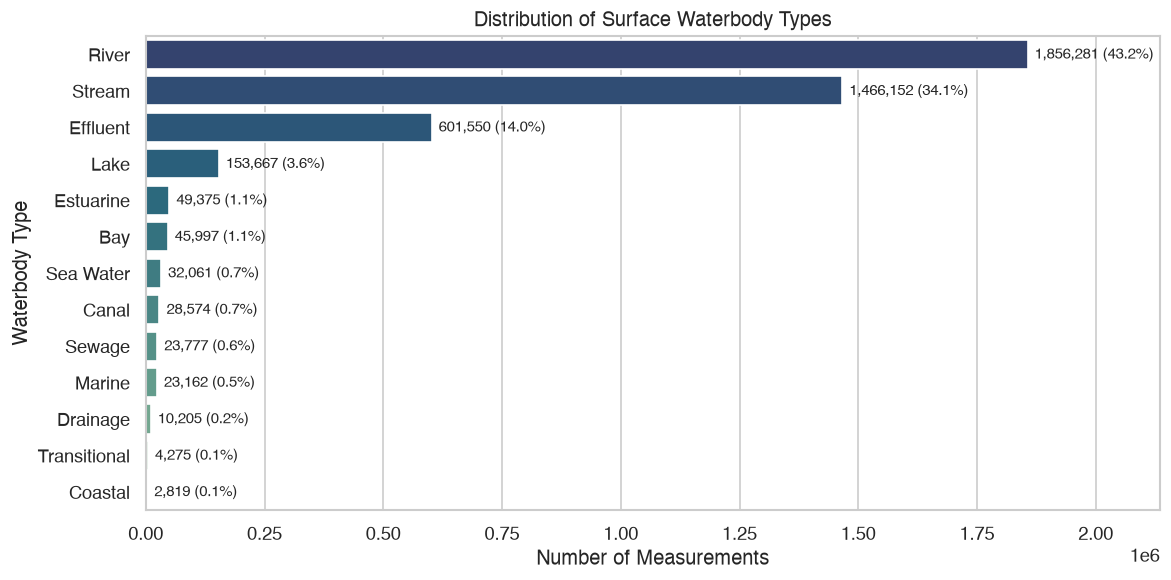

In [ ]:
# Waterbody Distribution
wb_counts = df['Waterbody Type'].value_counts()

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=wb_counts.values, y=wb_counts.index, palette='crest_r', hue=wb_counts.index, legend=False)
plt.title('Distribution of Surface Waterbody Types')
plt.xlabel('Number of Measurements')
plt.ylabel('Waterbody Type')

for i, v in enumerate(wb_counts.values):
    ax.text(v + 15000, i, f'{v:,} ({(v/len(df)*100):.1f}%)', va='center', fontsize=9)

plt.xlim(0, wb_counts.max() * 1.15)
plt.tight_layout()
plt.show()

## 5. Temporal Horizon & Sampling Frequency
Visualize sampling density across decades from 1940 to 2023.

Pre-2000 Records:  243,135 (5.66%)
2000–2023 Records: 4,054,760 (94.34%)


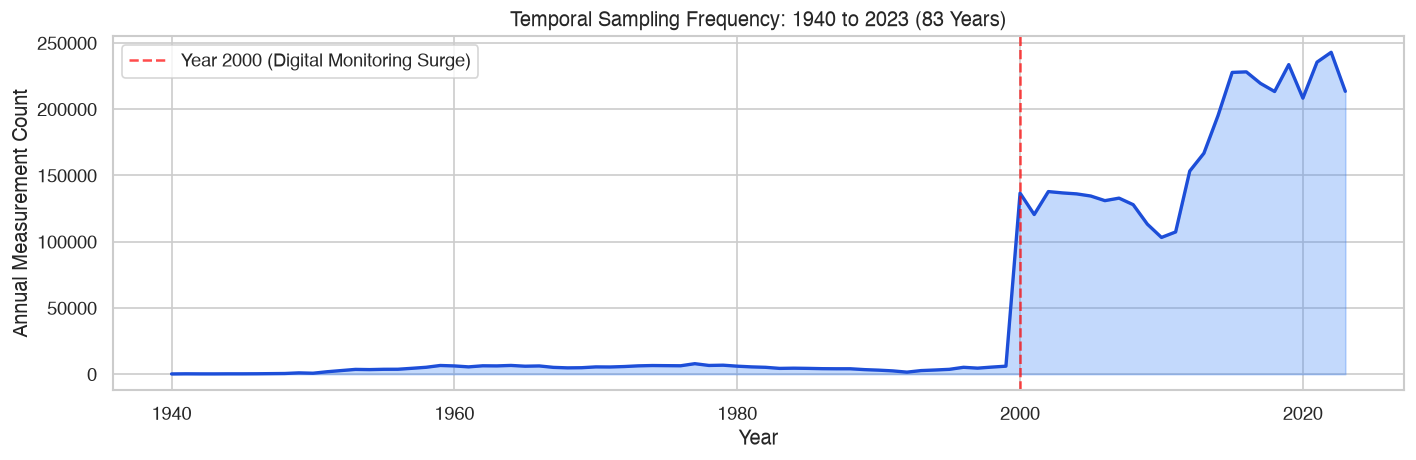

In [ ]:
# Temporal Coverage Chart
df['Year'] = pd.to_datetime(df['Date'], format='%d-%m-%Y', errors='coerce').dt.year
year_counts = df['Year'].value_counts().sort_index()

plt.figure(figsize=(12, 4))
plt.fill_between(year_counts.index, year_counts.values, color='#3b82f6', alpha=0.3)
plt.plot(year_counts.index, year_counts.values, color='#1d4ed8', lw=2)
plt.title('Temporal Sampling Frequency: 1940 to 2023 (83 Years)')
plt.xlabel('Year')
plt.ylabel('Annual Measurement Count')
plt.axvline(2000, color='red', linestyle='--', alpha=0.7, label='Year 2000 (Digital Monitoring Surge)')
plt.legend()
plt.tight_layout()
plt.show()

print(f"Pre-2000 Records:  {(df['Year'] < 2000).sum():,} ({(df['Year'] < 2000).mean()*100:.2f}%)")
print(f"2000–2023 Records: {(df['Year'] >= 2000).sum():,} ({(df['Year'] >= 2000).mean()*100:.2f}%)")

## 6. Spatial Monitoring Station Density
Audit station diversity and identify top water monitoring catchments.

Total Unique Monitoring Stations: 64,665


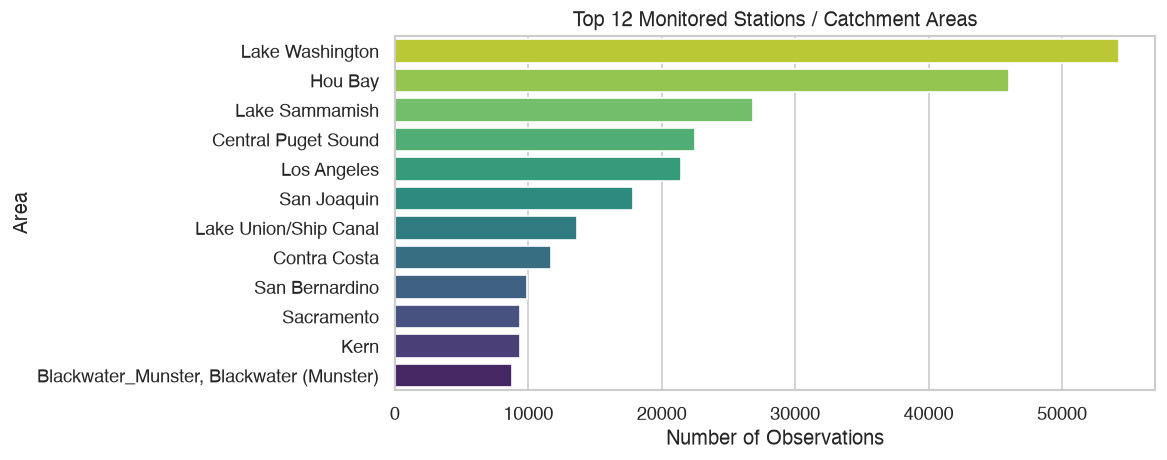

In [ ]:
# Top Monitoring Stations
total_stations = df['Area'].nunique()
top_stations = df['Area'].value_counts().head(12)

print(f"Total Unique Monitoring Stations: {total_stations:,}")

plt.figure(figsize=(10, 4))
sns.barplot(x=top_stations.values, y=top_stations.index, palette='viridis_r', hue=top_stations.index, legend=False)
plt.title('Top 12 Monitored Stations / Catchment Areas')
plt.xlabel('Number of Observations')
plt.tight_layout()
plt.show()

## 7. Export Profiling Summary Dataset
Save summary profile into `data/GeneratedOutput/01.EDA/` for downstream reference.

In [ ]:
# Export Summary Parquet
summary_profile = pd.DataFrame({
    'Metric': ['Total Rows', 'Total Columns', 'Total Unique Stations', 'Date Start', 'Date End', 'Top Country', 'Top Waterbody'],
    'Value': [
        f"{len(df):,}",
        f"{len(df.columns)}",
        f"{df['Area'].nunique():,}",
        str(df['Date'].min()),
        str(df['Date'].max()),
        f"{df['Country'].value_counts().index[0]} ({df['Country'].value_counts().iloc[0]:,})",
        f"{df['Waterbody Type'].value_counts().index[0]} ({df['Waterbody Type'].value_counts().iloc[0]:,})"
    ]
})

out_path = os.path.join(OUT_DIR, '01_dataset_summary_profile.parquet')
summary_profile.to_parquet(out_path, index=False, compression='snappy')
print(f"Exported: {out_path} ({os.path.getsize(out_path)} bytes)")
summary_profile

Exported: data/GeneratedOutput/01.EDA/01_dataset_summary_profile.parquet (1887 bytes)
